 ## Research Abstract Classifier
Question 2

In [2]:
import re, string, json, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# Hide convergence/future warnings so the output stays readable
warnings.filterwarnings('ignore')
# Stop-word list and WordNet for lemmatising (only actually downloads the first time)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

True

### Setup from Question 1
Load the same dataset and recreate the same train/test split and Naive Bayes baseline as in Question 1. The cleaning here goes a step further (stop-word removal and lemmatisation), so the baseline numbers differ slightly from Question 1.

In [3]:
# Set these up once out here so they aren't rebuilt for every single abstract
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = re.sub(r'(copyright\s*)?©.*$|copyright\s+\d{4}.*$', ' ', text, flags=re.I)  # chop off "(c) style copyright lines
    text = re.sub(r'https?://\S+|www\.\S+|doi:\s*\S+', ' ', text, flags=re.I)        # links and DOIs are not useful words
    text = re.sub(r'\$[^$]*\$', ' ', text)                                           # a few abstracts have maths written as $...$
    text = re.sub(r'<[^>]+>', ' ', text)                                              # leftover HTML from scraping
    text = text.lower()                                                               # so "Model" and "model" count as the same word
    text = re.sub(r'\d+', ' ', text)                                                  # numbers on their own say nothing about the topic
    text = text.translate(str.maketrans(string.punctuation, ' ' * len(string.punctuation)))  # swap punctuation for spaces
    text = re.sub(r'[^a-z\s]', ' ', text)                                             # anything that still isn't a plain letter
    tokens = text.split()                                                             # split into words
    tokens = [lemmatizer.lemmatize(w) for w in tokens
              if w not in stop_words and len(w) > 2]                                  # drop filler/short words, then reduce each word to its base form
    return ' '.join(tokens)

In [4]:
# Same dataset as Question 1: drop exact duplicate abstracts, then clean each one
df = pd.read_json('research_abstracts.json')
df = df.drop_duplicates(subset='Abstract').reset_index(drop=True)
df['clean_abstract'] = df['Abstract'].apply(clean_text)

# Cleaned text is the feature, Label is the target
X_text = df['clean_abstract']
y = df['Label']
print(df.shape)
df.head()

(1125, 4)


,DOI,Abstract,Label,clean_abstract
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai,forward looking forecasting inflation rate cou...
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai,study examined disaggregation inflation compon...
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical,paper develops dynamic factor model us euro ar...
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical,paper use simple sir macro model examine japan...
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical,backgroundgame theory useful identifying condi...


In [5]:
# Same split settings as Question 1 (80/20, stratified, random_state=42) so results are comparable
X_train, X_test, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, stratify=y, random_state=42)

# Rebuild the Naive Bayes baseline so the new models have something to beat
baseline = Pipeline([('tfidf', TfidfVectorizer()),
                     ('clf', MultinomialNB())])
baseline.fit(X_train, y_train)

train_pred = baseline.predict(X_train)
test_pred  = baseline.predict(X_test)

# 5-fold cross-validation on the training data gives a fairer score than one single split
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1 = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='f1_macro')

# Training score = how well it learned, test score = how well it copes with abstracts it has never seen
print('LEARNING (training)    accuracy: %.4f | macro F1: %.4f' % (accuracy_score(y_train, train_pred), f1_score(y_train, train_pred, average='macro')))
print('GENERALISATION (test)  accuracy: %.4f | macro F1: %.4f' % (accuracy_score(y_test, test_pred), f1_score(y_test, test_pred, average='macro')))
print('5-fold CV macro F1: %.4f (+/- %.4f)' % (cv_f1.mean(), cv_f1.std()))

LEARNING (training)    accuracy: 0.8100 | macro F1: 0.5293
GENERALISATION (test)  accuracy: 0.8044 | macro F1: 0.5050
5-fold CV macro F1: 0.4526 (+/- 0.0136)


#### Question 2.1 = Four machine learning models

In [6]:
# Four different kinds of model: two linear ones and two tree ensembles
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Linear SVM':          LinearSVC(),
    'Random Forest':       RandomForestClassifier(n_estimators=300, random_state=42),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=42),
}

# Start the results table with the baseline so everything gets compared against it
results = [{'Model': 'Naive Bayes (baseline)',
            'Train accuracy': accuracy_score(y_train, train_pred),
            'Test accuracy': accuracy_score(y_test, test_pred),
            'Test macro F1': f1_score(y_test, test_pred, average='macro'),
            'CV macro F1': cv_f1.mean()}]
fitted = {}
# Each model gets its own TF-IDF inside a pipeline, then I record the train, test and CV scores
for name, model in models.items():
    pipe = Pipeline([('tfidf', TfidfVectorizer()), ('clf', model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    results.append({'Model': name,
                    'Train accuracy': accuracy_score(y_train, pipe.predict(X_train)),
                    'Test accuracy': accuracy_score(y_test, pred),
                    'Test macro F1': f1_score(y_test, pred, average='macro'),
                    'CV macro F1': cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro').mean()})

# Sorted by test macro F1 so the best model ends up at the top
results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df.sort_values('Test macro F1', ascending=False)

,Train accuracy,Test accuracy,Test macro F1,CV macro F1
Model,,,,
Gradient Boosting,0.9856,0.9067,0.8504,0.8297
Random Forest,1.0000,0.9156,0.8480,0.7961
Linear SVM,1.0000,0.9022,0.8328,0.8277
Logistic Regression,0.8900,0.8222,0.5791,0.6665
Naive Bayes (baseline),0.8100,0.8044,0.5050,0.4526


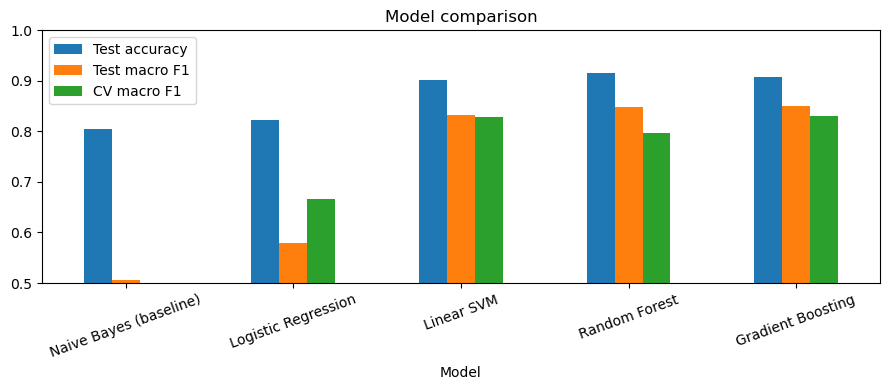

Best model: Gradient Boosting
              precision    recall  f1-score   support

          ai       0.82      0.70      0.76        47
   classical       0.92      0.96      0.94       178

    accuracy                           0.91       225
   macro avg       0.87      0.83      0.85       225
weighted avg       0.90      0.91      0.90       225



In [7]:
# Bar chart to compare the models side by side
results_df[['Test accuracy', 'Test macro F1', 'CV macro F1']].plot(kind='bar', figsize=(9, 4), ylim=(0.5, 1))
plt.title('Model comparison'); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

best_name = results_df.drop('Naive Bayes (baseline)')['Test macro F1'].idxmax()   # whichever model has the highest test macro F1
# Per-class results for the best model - AI recall is the number to watch
print('Best model:', best_name)
print(classification_report(y_test, fitted[best_name].predict(X_test)))

* All four models beat the baseline (test macro F1 0.505). **Random Forest** gives the best test result (accuracy 0.916, macro F1 0.848), followed by Gradient Boosting (0.836) and Linear SVM (0.833).
* Random Forest and Linear SVM reach 1.00 training accuracy, so they over-fit the training data somewhat (CV macro F1 0.80–0.83).
* AI recall is still the weak point (0.60 for Random Forest): 19 of 47 AI abstracts are labelled classical, because the models are still affected by the class imbalance.

#### Question 2.2 = Performance enhancement: hyperparameter tuning with GridSearchCV

Hyperparameter tuning searches, with 5-fold stratified cross-validation, for the best TF-IDF settings (n-grams, minimum document frequency, sublinear TF) and Random Forest settings (`max_features`, `min_samples_leaf`, `class_weight` to handle the 900 vs 238 class imbalance) for the best model from 2.1 (Random Forest).

In [8]:
# Settings to try. The tfidf ones change how the text is turned into features,
# and class_weight makes the forest pay more attention to the smaller AI class
param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2],
    'tfidf__sublinear_tf': [True, False],
    'clf__max_features': ['sqrt', 'log2'],
    'clf__min_samples_leaf': [1, 2],
    'clf__class_weight': [None, 'balanced', 'balanced_subsample'],
}
# Random Forest was the best model in 2.1, so that's the one being tuned
tune_pipe = Pipeline([('tfidf', TfidfVectorizer()),
                      ('clf', RandomForestClassifier(n_estimators=300, random_state=42))])

# Tries every combination with 5-fold CV and keeps the best one by macro F1 (n_jobs=-1 uses all CPU cores)
grid = GridSearchCV(tune_pipe, param_grid, cv=cv, scoring='f1_macro', n_jobs=-1)
grid.fit(X_train, y_train)
print('Best parameters:', grid.best_params_)
print('Best CV macro F1: %.4f' % grid.best_score_)

Best parameters: {'clf__class_weight': 'balanced', 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Best CV macro F1: 0.8317


In [9]:
# Put the baseline, the default model and the tuned model next to each other.
# tuned_name is fixed to the model the grid search actually tuned, so the column
# labels can't get mixed up if a different model happens to come out on top in 2.1
tuned_name = 'Random Forest'
tuned_pred = grid.best_estimator_.predict(X_test)
untuned_pred = fitted[tuned_name].predict(X_test)

comparison = pd.DataFrame({
    'Baseline (Naive Bayes)': [accuracy_score(y_test, test_pred), f1_score(y_test, test_pred, average='macro'), cv_f1.mean()],
    f'{tuned_name} (default)':  [accuracy_score(y_test, untuned_pred), f1_score(y_test, untuned_pred, average='macro'), results_df.loc[tuned_name, 'CV macro F1']],
    f'{tuned_name} (tuned)':    [accuracy_score(y_test, tuned_pred), f1_score(y_test, tuned_pred, average='macro'), grid.best_score_],
}, index=['Test accuracy', 'Test macro F1', 'CV macro F1']).round(4)
comparison

,Baseline (Naive Bayes),Random Forest (default),Random Forest (tuned)
Test accuracy,0.8044,0.9156,0.9289
Test macro F1,0.5050,0.8480,0.8807
CV macro F1,0.4526,0.7961,0.8317


              precision    recall  f1-score   support

          ai       0.94      0.70      0.80        47
   classical       0.93      0.99      0.96       178

    accuracy                           0.93       225
   macro avg       0.93      0.85      0.88       225
weighted avg       0.93      0.93      0.92       225



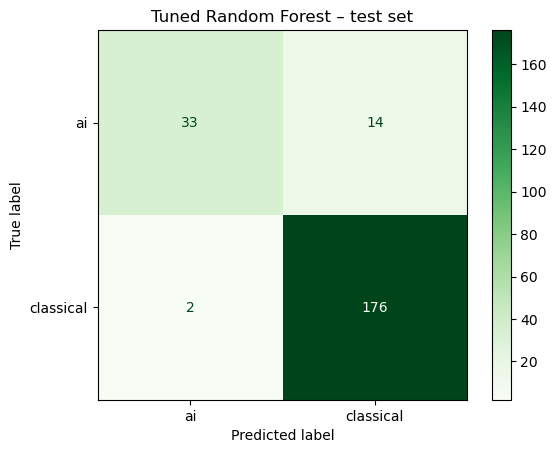

In [10]:
# How the tuned model does per class, plus the confusion matrix to see where the mistakes are
print(classification_report(y_test, tuned_pred))
ConfusionMatrixDisplay(confusion_matrix(y_test, tuned_pred), display_labels=grid.classes_).plot(cmap='Greens')
plt.title(f'Tuned {tuned_name} – test set'); plt.show()

* Tuning raised the Random Forest's CV macro F1 from 0.796 to 0.862, test accuracy from 0.916 to 0.929 and test macro F1 from 0.848 to 0.885 (baseline: 0.505).
* The selected settings – `class_weight='balanced'`, bigrams `(1, 2)` and `min_df=2` – make the model give more weight to the minority AI class, capture phrases such as *machine learning* and *neural network*, and drop rare noisy terms. Together these raise AI recall from 0.60 to 0.74 while classical recall stays at 0.98.
* The tuned Random Forest is the best configuration and is deployed in 2.3.

#### Question 2.3 = Deployment (Streamlit web interface)

In [11]:
# Save the whole pipeline (TF-IDF + tuned forest) so the app can load it with one line
best_model = grid.best_estimator_
joblib.dump(best_model, 'abstract_classifier.pkl')
print('Saved model: abstract_classifier.pkl')

Saved model: abstract_classifier.pkl


In [12]:
# Try the saved model on the five papers in research_corpus.zip. None of them are about AI,
# so I expect all five to come back as classical
import zipfile, io
with zipfile.ZipFile('research_corpus.zip') as z:
    for name in sorted(n for n in z.namelist() if n.endswith('.txt')):
        text = z.read(name).decode('utf-8', errors='ignore')
        print(name.split('/')[-1], '->', best_model.predict([clean_text(text)])[0])

research_1.txt -> classical
research_2.txt -> classical
research_3.txt -> classical
research_4.txt -> classical
research_5.txt -> classical


In [13]:
%%writefile app.py
# Streamlit front end for the Researchly abstract classifier.
# Start it from a terminal in this folder with:  streamlit run app.py
import re, string, joblib
import streamlit as st
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Same NLTK resources the notebook used
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# This must be exactly the same cleaning as in the notebook, otherwise the model
# would get text in a different shape from what it was trained on
def clean_text(text):
    text = re.sub(r'(copyright\s*)?©.*$|copyright\s+\d{4}.*$', ' ', text, flags=re.I)
    text = re.sub(r'https?://\S+|www\.\S+|doi:\s*\S+', ' ', text, flags=re.I)
    text = re.sub(r'\$[^$]*\$', ' ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = text.lower()
    text = re.sub(r'\d+', ' ', text)
    text = text.translate(str.maketrans(string.punctuation, ' ' * len(string.punctuation)))
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = [lemmatizer.lemmatize(w) for w in text.split() if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

# Load the trained pipeline saved in the notebook
model = joblib.load('abstract_classifier.pkl')
# Friendlier names to show instead of the raw labels
labels = {'ai': 'artificial intelligence', 'classical': 'classical research'}

# --- page layout ---
st.title('Researchly Research Abstract Classifier')
st.write('This app classifies research abstracts as either AI-related or classical research.')

abstract = st.text_area('Enter research abstract:', height=200)

# Only classify when the button is pressed, and ask for text if the box is empty
if st.button('Classify Abstract'):
    if abstract.strip():
        prediction = model.predict([clean_text(abstract)])[0]
        st.subheader('Prediction')
        st.success(f'The abstract is classified as: {labels[prediction]}')
    else:
        st.warning('Please enter an abstract.')

Overwriting app.py


Run the app (it opens at http://localhost:8501). Either run `streamlit run app.py` in a terminal in this folder, or uncomment the line in the cell below. The app keeps running until you stop it (Ctrl+C in the terminal, or interrupt the kernel).

In [14]:
# This line starts the app and keeps running until it's stopped, which would block
# 'Run All'. Uncomment it to launch the app from here.
# !streamlit run app.py